# Spiking Statistics Summary

This notebook reads the saved `spiking_stats` artifacts from a training run and summarizes the end of training using batch indices:

- mean spike rate
- spike rate std across neurons
- fraction of silent neurons
- fraction of saturated neurons
- membrane mean/std when available

It also includes an optional animated heatmap section that will run only if time-by-neuron trace files are available.

In [21]:
from pathlib import Path
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 50)

In [22]:
# Point this at a run directory or directly at its spiking_stats directory.
# Examples:
# RUN_DIR = Path('../logs/snn/2026-04-02_20-49-45_033955_snn_pid238748')
# RUN_DIR = Path('../logs/snn/2026-03-21/2026-03-21_16-36-23_555680_snn_pid1621149')
RUN_DIR = Path('../logs/snn/2026-04-03/2026-04-03_12-34-40_539620_snn_pid42483')
TAIL_BATCH_WINDOW = 200

if RUN_DIR.name == 'spiking_stats':
    SPIKING_DIR = RUN_DIR
    RUN_DIR = RUN_DIR.parent
else:
    SPIKING_DIR = RUN_DIR / 'spiking_stats'

print('Run dir:', RUN_DIR.resolve())
print('Spiking stats dir:', SPIKING_DIR.resolve())
assert SPIKING_DIR.exists(), f'Spiking stats directory not found: {SPIKING_DIR}'

Run dir: /home/alex/snn_for_bts/brain_to_text/model_training/logs/snn/2026-04-03/2026-04-03_12-34-40_539620_snn_pid42483
Spiking stats dir: /home/alex/snn_for_bts/brain_to_text/model_training/logs/snn/2026-04-03/2026-04-03_12-34-40_539620_snn_pid42483/spiking_stats


In [23]:
def load_jsonl(path: Path):
    if not path.exists():
        return []
    records = []
    with path.open('r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if line:
                records.append(json.loads(line))
    return records

per_batch = load_jsonl(SPIKING_DIR / 'per_batch.jsonl')
per_epoch = load_jsonl(SPIKING_DIR / 'per_epoch.jsonl')
latest_summary = None
summary_path = SPIKING_DIR / 'summary.json'
if summary_path.exists():
    latest_summary = json.loads(summary_path.read_text(encoding='utf-8'))

print(f'Loaded {len(per_batch)} batch records')
print(f'Loaded {len(per_epoch)} epoch records')
print('Latest summary available:', latest_summary is not None)

Loaded 16000 batch records
Loaded 1 epoch records
Latest summary available: True


In [24]:
def flatten_records(records, index_key):
    rows = []
    for record in records:
        idx = record.get(index_key)
        for layer_name, layer_stats in record.get('layers', {}).items():
            row = {index_key: idx, 'layer': layer_name}
            row.update(layer_stats)
            rows.append(row)
    return pd.DataFrame(rows)

batch_df = flatten_records(per_batch, 'batch_index')
epoch_df = flatten_records(per_epoch, 'epoch_index')

metrics_of_interest = [
    'mean_spike_rate',
    'spike_rate_std_across_neurons',
    'fraction_silent_neurons',
    'fraction_saturated_neurons',
    'membrane_mean',
    'membrane_std',
]

batch_df.tail()

,batch_index,layer,mean_spike_rate,spike_rate_std_across_neurons,fraction_silent_neurons,fraction_saturated_neurons,num_neurons,membrane_mean,membrane_std,threshold_mean,threshold_std,threshold_min,threshold_max,gradient_norm
63995,15998,backbone.snn_core.3.block.1,0.135831,0.064854,0.000000,0.0,6144,-0.823939,1.191647,0.75,0.0,0.75,0.75,0.282622
63996,15999,backbone.snn_core.0.block.1,0.084547,0.080814,0.006836,0.0,6144,-0.440795,0.864679,0.75,0.0,0.75,0.75,0.831430
63997,15999,backbone.snn_core.1.block.1,0.090509,0.069778,0.000977,0.0,6144,-0.508585,1.098992,0.75,0.0,0.75,0.75,2.178162
63998,15999,backbone.snn_core.2.block.1,0.104355,0.070314,0.000163,0.0,6144,-0.771416,1.405232,0.75,0.0,0.75,0.75,0.558429
63999,15999,backbone.snn_core.3.block.1,0.118252,0.072853,0.000000,0.0,6144,-0.856435,1.251331,0.75,0.0,0.75,0.75,0.507679


In [25]:
if batch_df.empty:
    print('No per-batch spiking statistics found.')
else:
    available_metrics = [m for m in metrics_of_interest if m in batch_df.columns]
    last_batch = int(batch_df['batch_index'].max())
    first_batch = max(int(batch_df['batch_index'].min()), last_batch - TAIL_BATCH_WINDOW + 1)
    tail_df = batch_df[batch_df['batch_index'].between(first_batch, last_batch)].copy()
    print(f'Summarizing batches {first_batch}..{last_batch} ({tail_df["batch_index"].nunique()} logged batches)')
    summary_table = (
        tail_df[['layer'] + available_metrics]
        .groupby('layer')
        .agg(['mean', 'std', 'min', 'max'])
    )
    display(summary_table)


Summarizing batches 15800..15999 (200 logged batches)


mean_spike_rate                                \
                                       mean       std       min       max   
layer                                                                       
backbone.snn_core.0.block.1        0.098934  0.007912  0.080702  0.115234   
backbone.snn_core.1.block.1        0.106206  0.006866  0.090199  0.120950   
backbone.snn_core.2.block.1        0.117897  0.005945  0.103240  0.130141   
backbone.snn_core.3.block.1        0.131603  0.005837  0.116655  0.144748   

                            spike_rate_std_across_neurons                      \
                                                     mean       std       min   
layer                                                                           
backbone.snn_core.0.block.1                      0.078628  0.003134  0.071666   
backbone.snn_core.1.block.1                      0.067925  0.002512  0.062395   
backbone.snn_core.2.block.1                      0.066975  0.002622  0.060199   
backbone.snn_core.3.block.1                      0.067796  0.003004  0.060287   

                                      fraction_silent_neurons            \
                                  max                    mean       std   
layer                                                                     
backbone.snn_core.0.block.1  0.087824                0.008662  0.004981   
backbone.snn_core.1.block.1  0.075604                0.002599  0.002246   
backbone.snn_core.2.block.1  0.076660                0.000920  0.001041   
backbone.snn_core.3.block.1  0.077822                0.000312  0.000662   

                                                fraction_saturated_neurons  \
                                  min       max                       mean   
layer                                                                        
backbone.snn_core.0.block.1  0.002767  0.039388                        0.0   
backbone.snn_core.1.block.1  0.000326  0.020671                        0.0   
backbone.snn_core.2.block.1  0.000000  0.009440                        0.0   
backbone.snn_core.3.block.1  0.000000  0.006022                        0.0   

                                           membrane_mean                      \
                             std  min  max          mean       std       min   
layer                                                                          
backbone.snn_core.0.block.1  0.0  0.0  0.0     -0.446305  0.028996 -0.540779   
backbone.snn_core.1.block.1  0.0  0.0  0.0     -0.440489  0.053899 -0.642794   
backbone.snn_core.2.block.1  0.0  0.0  0.0     -0.713466  0.071879 -0.988042   
backbone.snn_core.3.block.1  0.0  0.0  0.0     -0.833875  0.051668 -1.016714   

                                      membrane_std                      \
                                  max         mean       std       min   
layer                                                                    
backbone.snn_core.0.block.1 -0.388765     0.870742  0.036785  0.798341   
backbone.snn_core.1.block.1 -0.325809     0.989172  0.094733  0.815021   
backbone.snn_core.2.block.1 -0.579991     1.275369  0.113027  1.041046   
backbone.snn_core.3.block.1 -0.714401     1.211440  0.059698  1.081535   

                                       
                                  max  
layer                                  
backbone.snn_core.0.block.1  1.043116  
backbone.snn_core.1.block.1  1.425774  
backbone.snn_core.2.block.1  1.755559  
backbone.snn_core.3.block.1  1.442602

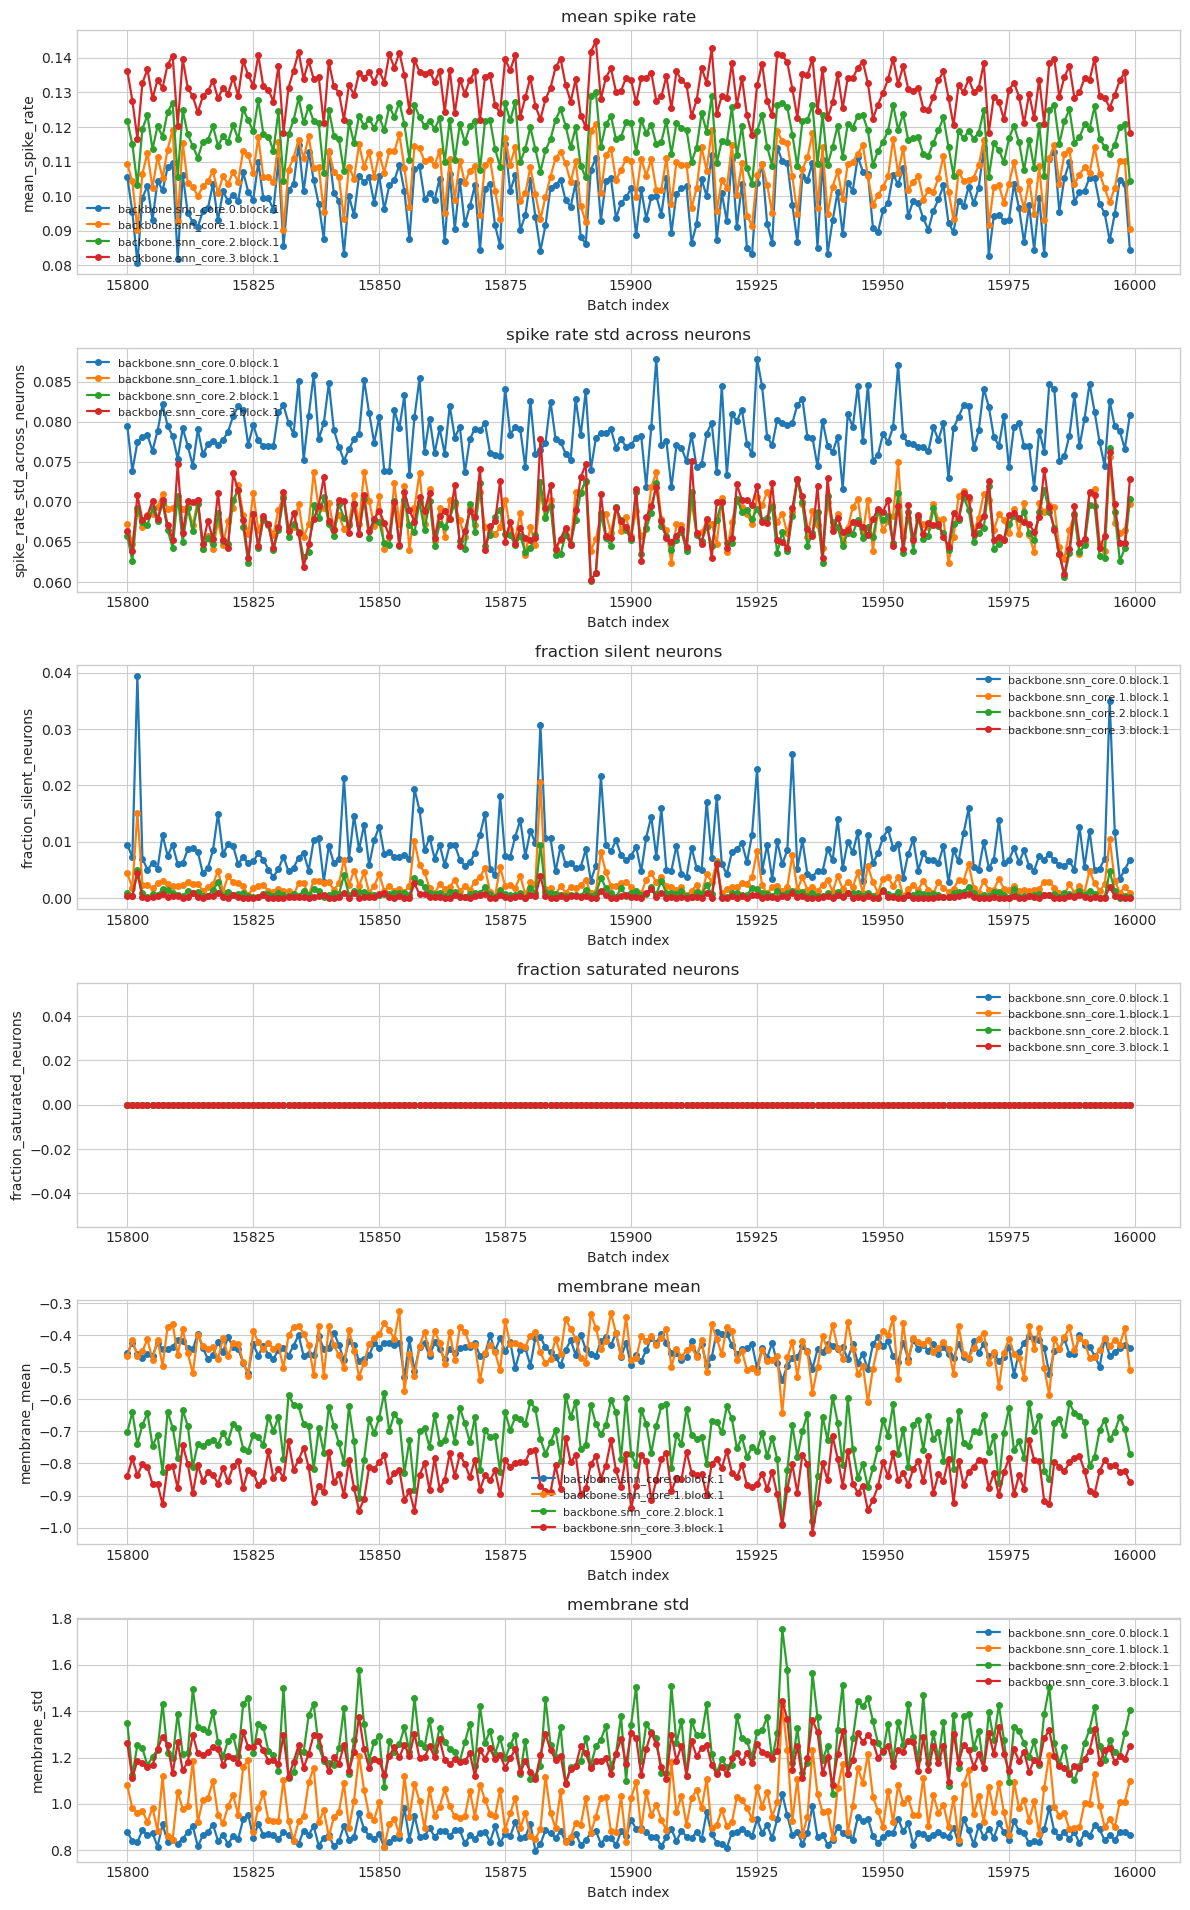

In [26]:
if not batch_df.empty:
    available_metrics = [m for m in metrics_of_interest if m in batch_df.columns]
    if available_metrics:
        last_batch = int(batch_df['batch_index'].max())
        first_batch = max(int(batch_df['batch_index'].min()), last_batch - TAIL_BATCH_WINDOW + 1)
        tail_df = batch_df[batch_df['batch_index'].between(first_batch, last_batch)].copy()
        fig, axes = plt.subplots(len(available_metrics), 1, figsize=(12, 3.2 * len(available_metrics)), squeeze=False)
        for ax, metric in zip(axes[:, 0], available_metrics):
            plotted = False
            for layer_name, layer_df in tail_df.groupby('layer'):
                series = layer_df[['batch_index', metric]].dropna().sort_values('batch_index')
                if series.empty:
                    continue
                ax.plot(series['batch_index'], series[metric], marker='o', linewidth=1.6, markersize=4, label=layer_name)
                plotted = True
            ax.set_title(metric.replace('_', ' '))
            ax.set_xlabel('Batch index')
            ax.set_ylabel(metric)
            if plotted:
                ax.legend(fontsize=8, loc='best')
        plt.tight_layout()
        plt.show()
    else:
        print('None of the requested summary metrics are present in per_batch.jsonl.')

,layer,mean_spike_rate,spike_rate_std_across_neurons,fraction_silent_neurons,fraction_saturated_neurons,membrane_mean,membrane_std
63996,backbone.snn_core.0.block.1,0.084547,0.080814,0.006836,0.0,-0.440795,0.864679
63997,backbone.snn_core.1.block.1,0.090509,0.069778,0.000977,0.0,-0.508585,1.098992
63998,backbone.snn_core.2.block.1,0.104355,0.070314,0.000163,0.0,-0.771416,1.405232
63999,backbone.snn_core.3.block.1,0.118252,0.072853,0.000000,0.0,-0.856435,1.251331


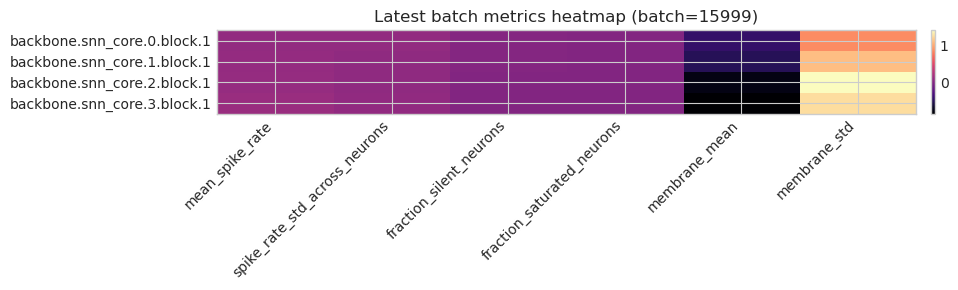

In [27]:
if not batch_df.empty:
    available_metrics = [m for m in metrics_of_interest if m in batch_df.columns]
    if available_metrics:
        latest_batch = int(batch_df['batch_index'].max())
        latest_batch_df = batch_df[batch_df['batch_index'] == latest_batch].copy()
        display(latest_batch_df[['layer'] + available_metrics].sort_values('layer'))

        heatmap_df = latest_batch_df.set_index('layer')[available_metrics]
        fig, ax = plt.subplots(figsize=(10, max(3, 0.5 * len(heatmap_df))))
        im = ax.imshow(heatmap_df.fillna(np.nan).to_numpy(), aspect='auto', interpolation='nearest', cmap='magma')
        ax.set_xticks(range(len(heatmap_df.columns)))
        ax.set_xticklabels(heatmap_df.columns, rotation=45, ha='right')
        ax.set_yticks(range(len(heatmap_df.index)))
        ax.set_yticklabels(heatmap_df.index)
        ax.set_title(f'Latest batch metrics heatmap (batch={latest_batch})')
        fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
        plt.tight_layout()
        plt.show()
    else:
        print('No requested metrics found in per_batch.jsonl.')
else:
    print('No per-batch spiking statistics found.')

## Optional Animated Heatmap

A true animated heatmap needs a time-by-neuron trace such as spike activity or membrane voltage. The current saved `spiking_stats` files contain summary statistics only, so this section will only run if separate trace arrays already exist in the run directory.

Supported formats below:
- `.npz` file with an array named `trace`
- `.npy` file containing a `time x neurons` array

In [ ]:
TRACE_DIR_CANDIDATES = [
    SPIKING_DIR / 'activity_heatmaps',
    RUN_DIR / 'activity_heatmaps',
    RUN_DIR / 'analysis_exports',
]

trace_files = []
for trace_dir in TRACE_DIR_CANDIDATES:
    if trace_dir.exists():
        trace_files.extend(sorted(trace_dir.glob('*.npz')))
        trace_files.extend(sorted(trace_dir.glob('*.npy')))

print('Found trace files:', len(trace_files))
print(TRACE_DIR_CANDIDATES)
for path in trace_files[:20]:
    print('-', path)

Found trace files: 0


NameError: name 'path' is not defined

In [29]:
def load_trace(path: Path):
    if path.suffix == '.npz':
        data = np.load(path)
        if 'trace' not in data:
            raise KeyError(f"'trace' array not found in {path}")
        trace = data['trace']
    else:
        trace = np.load(path)
    trace = np.asarray(trace)
    if trace.ndim != 2:
        raise ValueError(f'Expected 2D trace array, got shape {trace.shape}')
    return trace

def reshape_to_square(frame):
    side = int(math.ceil(math.sqrt(frame.shape[0])))
    padded = np.full(side * side, np.nan, dtype=np.float32)
    padded[: frame.shape[0]] = frame.astype(np.float32)
    return padded.reshape(side, side)

if trace_files:
    TRACE_PATH = trace_files[0]
    trace = load_trace(TRACE_PATH)
    print('Using trace:', TRACE_PATH)
    print('Trace shape:', trace.shape)

    max_neurons = min(128, trace.shape[1])
    trace = trace[:, :max_neurons]

    fig, ax = plt.subplots(figsize=(10, 4))
    im = ax.imshow(trace.T, aspect='auto', origin='lower', interpolation='nearest', cmap='viridis')
    ax.set_title(f'Static heatmap: {TRACE_PATH.name}')
    ax.set_xlabel('Time step')
    ax.set_ylabel('Neuron')
    fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(5, 5))
    image = ax.imshow(reshape_to_square(trace[0]), interpolation='nearest', cmap='viridis')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'{TRACE_PATH.name} | t=0')
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

    def update(frame_idx):
        image.set_data(reshape_to_square(trace[frame_idx]))
        ax.set_title(f'{TRACE_PATH.name} | t={frame_idx}')
        return (image,)

    anim = animation.FuncAnimation(fig, update, frames=trace.shape[0], interval=120, blit=False)
    plt.close(fig)
    display(HTML(anim.to_jshtml()))
else:
    print('No trace arrays found. Summary statistics are available, but animated heatmaps require saved time-by-neuron traces.')

No trace arrays found. Summary statistics are available, but animated heatmaps require saved time-by-neuron traces.
